## 1. Setup

In [1]:
from __future__ import annotations
import sys, json
from pathlib import Path

PROJECT_ROOT = Path().resolve().parents[1]
W4_SRC = PROJECT_ROOT / "workshops" / "w4" / "src"
for _p in (str(W4_SRC),):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from constants import CHECKPOINTS_DIR, RUNS_DIR, FIGURES_DIR, SEED
from autoencoder.data_loader import load_w1_data
from train.train_ae  import load_checkpoint as ae_load_checkpoint, set_seed
from train.train_vae import load_checkpoint as vae_load_checkpoint
from evaluate.anomaly_detection import (
    AnomalyConfig, AnomalyScorer, ThresholdSelector, AnomalyEvaluator, CumulativeResults,
)

ANOMALY_DIR = RUNS_DIR / "anomaly"
ANOMALY_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cpu


## 2. Data

In [2]:
df, y_all, _, _, _, split = load_w1_data()

# Preprocessor from ae_best.pt — same one used by AE and VAE
_, _, prep, _, _ = ae_load_checkpoint(CHECKPOINTS_DIR / "ae_best.pt", DEVICE)

tune_idx = split["tune"]
test_idx = split["test"]

df_tune = df.iloc[tune_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)
y_tune  = y_all[tune_idx]
y_test  = y_all[test_idx]

x_num_tune, x_cat_tune = prep.transform(df_tune)
x_num_test, x_cat_test = prep.transform(df_test)

print(f"tune  : {len(x_num_tune):,}  churn={y_tune.sum():,}  prevalence={y_tune.mean():.3%}")
print(f"test  : {len(x_num_test):,}  churn={y_test.sum():,}  prevalence={y_test.mean():.3%}")

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 63) | users in both labelled months: 881701
tune  : 124,115  churn=7,933  prevalence=6.392%
test  : 970,960  churn=87,330  prevalence=8.994%


## 3. Load checkpoints

In [3]:
ae_model,  ae_cfg,  _, _, _ = ae_load_checkpoint( CHECKPOINTS_DIR / "ae_best.pt",  DEVICE)
vae_model, vae_cfg, _, _, _ = vae_load_checkpoint(CHECKPOINTS_DIR / "vae_best.pt", DEVICE)

print(f"AE  — z_dim={ae_cfg.z_dim}")
print(f"VAE — z_dim={vae_cfg.z_dim}  beta={vae_cfg.beta}")

cfg    = AnomalyConfig()
scorer = AnomalyScorer(ae_model, vae_model, DEVICE, cfg)

AE  — z_dim=16
VAE — z_dim=16  beta=1.0


## 4. Compute anomaly scores

In [4]:
scores_tune = scorer.scores(x_num_tune, x_cat_tune)
scores_test = scorer.scores(x_num_test, x_cat_test)

for name, arr in scores_tune.items():
    print(f"{name:15s}  tune min={arr.min():.3f}  max={arr.max():.3f}  mean={arr.mean():.3f}")

AE_recon         tune min=0.040  max=520.073  mean=2.781
VAE_recon        tune min=0.095  max=235.202  mean=6.559
VAE_recon_kl     tune min=4.757  max=267.653  mean=16.254


## 5. Ranking metrics (AUC-ROC, AP)

In [5]:
ev = AnomalyEvaluator()
rows = []
for name in cfg.score_names:
    tune_m = ev.ranking_metrics(scores_tune[name], y_tune)
    test_m = ev.ranking_metrics(scores_test[name], y_test)
    rows.append({
        "score":              name,
        "roc_auc_tune":       tune_m["roc_auc"],
        "ap_tune":            tune_m["average_precision"],
        "roc_auc_test":       test_m["roc_auc"],
        "ap_test":            test_m["average_precision"],
    })

rank_df = pd.DataFrame(rows)
print(rank_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nRandom AP baseline (test prevalence): {y_test.mean():.4f}")

       score  roc_auc_tune  ap_tune  roc_auc_test  ap_test
    AE_recon        0.7717   0.2719        0.7823   0.3248
   VAE_recon        0.7414   0.2441        0.7589   0.2947
VAE_recon_kl        0.7970   0.3266        0.8116   0.3882

Random AP baseline (test prevalence): 0.0899


## 6. Threshold selection on tune set

In [6]:
sel = ThresholdSelector(criterion="max_f1")
thresholds = {}
for name in cfg.score_names:
    t = sel.fit(scores_tune[name], y_tune)
    thresholds[name] = t
    print(f"{name:15s}  threshold={t:.4f}")

with open(ANOMALY_DIR / "anomaly_thresholds.json", "w") as f:
    json.dump(thresholds, f, indent=2)
print("\nSaved: anomaly_thresholds.json")

AE_recon         threshold=7.0802
VAE_recon        threshold=14.8182
VAE_recon_kl     threshold=27.2810

Saved: anomaly_thresholds.json


## 7. Decision metrics on test (threshold from tune)

In [7]:
metric_rows = []
for name in cfg.score_names:
    r_m  = ev.ranking_metrics(scores_test[name], y_test)
    d_m  = ev.decision_metrics(scores_test[name], y_test, thresholds[name])
    row  = {"score": name, "family": "unsupervised", "workshop": "W4",
            "supervision": "unsupervised"}
    row.update(r_m)
    row.update(d_m)
    metric_rows.append(row)

metrics_df = pd.DataFrame(metric_rows)
print(metrics_df[[
    "score", "roc_auc", "average_precision", "threshold",
    "precision_churn", "recall_churn", "f1_churn", "balanced_accuracy",
]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

metrics_df.to_csv(ANOMALY_DIR / "anomaly_metrics.csv", index=False)

       score  roc_auc  average_precision  threshold  precision_churn  recall_churn  f1_churn  balanced_accuracy
    AE_recon   0.7823             0.3248     7.0802           0.3455        0.3333    0.3393             0.6355
   VAE_recon   0.7589             0.2947    14.8182           0.3508        0.2562    0.2962             0.6047
VAE_recon_kl   0.8116             0.3882    27.2810           0.4175        0.4132    0.4153             0.6781


## 8. Figures

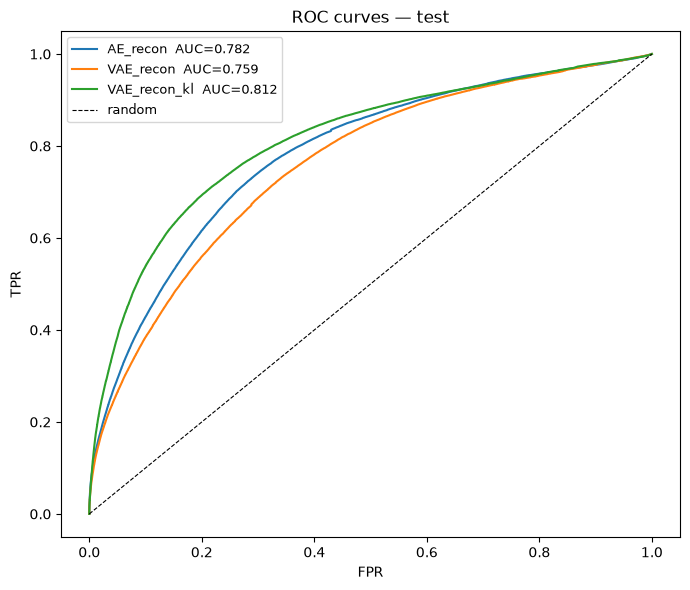

In [8]:
# ROC curves
fig, ax = plt.subplots(figsize=(7, 6))
for name in cfg.score_names:
    c = ev.curves(scores_test[name], y_test)
    auc = ev.ranking_metrics(scores_test[name], y_test)["roc_auc"]
    ax.plot(c["fpr"], c["tpr"], label=f"{name}  AUC={auc:.3f}")
ax.plot([0,1],[0,1], "k--", linewidth=0.8, label="random")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
ax.set_title("ROC curves — test"); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "anomaly_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

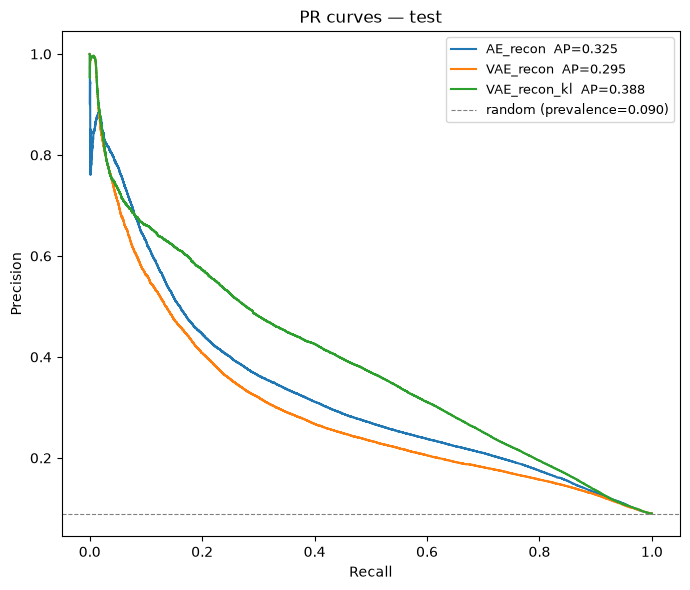

In [9]:
# PR curves
fig, ax = plt.subplots(figsize=(7, 6))
for name in cfg.score_names:
    c  = ev.curves(scores_test[name], y_test)
    ap = ev.ranking_metrics(scores_test[name], y_test)["average_precision"]
    ax.plot(c["recall"], c["precision"], label=f"{name}  AP={ap:.3f}")
ax.axhline(y_test.mean(), linestyle="--", color="gray", linewidth=0.8,
           label=f"random (prevalence={y_test.mean():.3f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("PR curves — test"); ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "anomaly_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

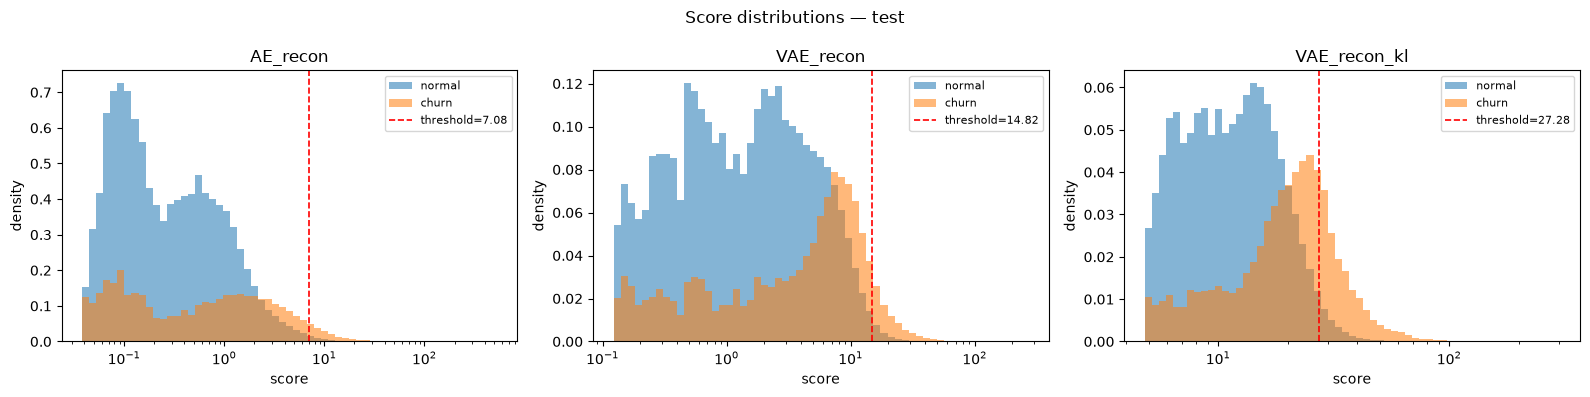

In [10]:
# Score distributions
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, cfg.score_names):
    s_n = scores_test[name][y_test == 0]
    s_c = scores_test[name][y_test == 1]
    low  = min(s_n.min(), s_c.min())
    high = max(s_n.max(), s_c.max())
    bins = np.logspace(np.log10(max(low, 1e-3)), np.log10(high), 60)
    ax.hist(s_n, bins=bins, alpha=0.55, density=True, label="normal")
    ax.hist(s_c, bins=bins, alpha=0.55, density=True, label="churn")
    ax.axvline(thresholds[name], color="red", linestyle="--", linewidth=1.2,
               label=f"threshold={thresholds[name]:.2f}")
    ax.set_xscale("log"); ax.set_title(name)
    ax.set_xlabel("score"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.suptitle("Score distributions — test", fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "anomaly_score_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

Best score by AUC: VAE_recon_kl


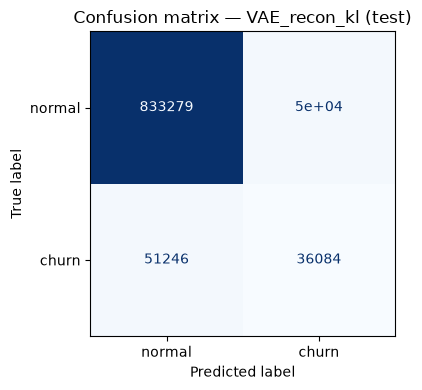

In [11]:
# Confusion matrix — best score by AUC
best_score = metrics_df.sort_values("roc_auc", ascending=False).iloc[0]["score"]
print(f"Best score by AUC: {best_score}")

y_pred = (scores_test[best_score] >= thresholds[best_score]).astype(int)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["normal", "churn"],
    cmap="Blues", ax=ax, colorbar=False,
)
ax.set_title(f"Confusion matrix — {best_score} (test)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "anomaly_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Cumulative results W1 + W2 + W4

In [12]:
anomaly_for_cum = metrics_df[["score", "roc_auc", "average_precision",
                               "precision_churn", "recall_churn", "f1_churn",
                               "threshold", "workshop", "supervision"]].copy()
anomaly_for_cum = anomaly_for_cum.rename(columns={"score": "model"})
anomaly_for_cum["family"] = "autoencoder"

cum = CumulativeResults()
cumulative_df = cum.build(anomaly_for_cum)
cumulative_df.to_csv(ANOMALY_DIR / "cumulative_results.csv", index=False)
print(cumulative_df[[
    "model", "family", "workshop", "supervision",
    "roc_auc", "average_precision", "f1_churn",
]].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

       model       family workshop  supervision  roc_auc  average_precision  f1_churn
          M2 randomforest       W1   supervised   0.8632             0.5933    0.5840
          M3      xgboost       W1   supervised   0.8520             0.5882    0.5740
        LSTM         lstm       W2   supervised   0.8507             0.5801    0.5780
          M1     logistic       W1   supervised   0.8445             0.5553    0.5567
VAE_recon_kl  autoencoder       W4 unsupervised   0.8116             0.3882    0.4153
    AE_recon  autoencoder       W4 unsupervised   0.7823             0.3248    0.3393
   VAE_recon  autoencoder       W4 unsupervised   0.7589             0.2947    0.2962


## 10. Summary

In [13]:
best = metrics_df.sort_values("roc_auc", ascending=False).iloc[0]
sup_best = cumulative_df[cumulative_df["supervision"] == "supervised"].iloc[0]

print("=== Anomaly detection summary ===")
print(f"Best detector   : {best['score']}")
print(f"  AUC-ROC       : {best['roc_auc']:.4f}")
print(f"  Avg Precision : {best['average_precision']:.4f}")
print(f"  F1 churn      : {best['f1_churn']:.4f}")
print(f"  Recall churn  : {best['recall_churn']:.4f}")
print(f"  Precision     : {best['precision_churn']:.4f}")
print(f"  Threshold     : {best['threshold']:.4f}  (selected on tune; test prevalence={y_test.mean():.3%})")

print(f"\nBest supervised : {sup_best['model']} ({sup_best['family']}, {sup_best['workshop']})")
print(f"  AUC-ROC       : {sup_best['roc_auc']:.4f}")

vae_r = metrics_df[metrics_df["score"] == "VAE_recon"].iloc[0]
vae_k = metrics_df[metrics_df["score"] == "VAE_recon_kl"].iloc[0]
print(f"\nVAE_recon AUC={vae_r['roc_auc']:.4f}  vs  VAE_recon_kl AUC={vae_k['roc_auc']:.4f}")
print("recon+KL improves over recon only:", vae_k['roc_auc'] > vae_r['roc_auc'])

=== Anomaly detection summary ===
Best detector   : VAE_recon_kl
  AUC-ROC       : 0.8116
  Avg Precision : 0.3882
  F1 churn      : 0.4153
  Recall churn  : 0.4132
  Precision     : 0.4175
  Threshold     : 27.2810  (selected on tune; test prevalence=8.994%)

Best supervised : M2 (randomforest, W1)
  AUC-ROC       : 0.8632

VAE_recon AUC=0.7589  vs  VAE_recon_kl AUC=0.8116
recon+KL improves over recon only: True
